# Univariate signal research

Which of the 17 price/volume features carry a non-zero cross-sectional rank IC with forward returns, how quickly
that information decays, and what do the gross long-short spreads and turnover look like? Research sample only:
the holdout is never read. All numbers come from `python -m src.run_signal_research`; this notebook loads its
outputs and holds the interpretation. Design and conventions: README, "Signal research".

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, "..")

from src import signal_plots as plots
from src.signal_report import half_life_table, headline_table, period_table, survivors, terminal_effect

OUT = Path("../reports/signal_research")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)
read = lambda name: pd.read_csv(OUT / f"{name}.csv")

meta = json.loads((OUT / "run_metadata.json").read_text())
headline, ic = headline_table(OUT), read("ic_summary")
{k: meta[k] for k in ["first_research_date", "last_research_date", "n_research_dates", "n_research_rows",
                      "holdout_start", "embargo_trading_days", "n_tests"]}

{'first_research_date': '1999-01-04',
 'last_research_date': '2021-11-30',
 'n_research_dates': 5766,
 'n_research_rows': 2890984,
 'holdout_start': '2022-01-01',
 'embargo_trading_days': 22,
 'n_tests': 51}

The research sample runs 1999-01-04 to 2021-11-30 (5,766 dates, about 2.9m stock-days of point-in-time S&P 500
members). The last 22 trading days before the 2022-01-01 holdout are embargoed so that no label or shifted return
reaches into it. There are 51 IC tests (17 features x 3 horizons).

## 1. Which signals have a non-zero IC after multiple-testing correction?

In [2]:
counts = pd.Series({
    "|t| > 3": int(ic["abs_t_gt3"].sum()),
    "Holm (5%)": int(ic["reject_holm"].sum()),
    "Benjamini-Yekutieli (5%)": int(ic["reject_by"].sum()),
    "Benjamini-Hochberg (5%)": int(ic["reject_bh"].sum()),
    "unadjusted p < 5%": int((ic["p_value"] < 0.05).sum()),
}, name="rejected of 51")
display(counts)
display(survivors(headline, "bh")[["feature", "horizon", "ic_mean", "nw_t", "p_value_holm", "p_value_bh",
                                  "reject_holm", "reject_by", "expected_sign", "ls_sharpe_gross", "turnover"]].round(4))

|t| > 3                     13
Holm (5%)                   11
Benjamini-Yekutieli (5%)    14
Benjamini-Hochberg (5%)     18
unadjusted p < 5%           27
Name: rejected of 51, dtype: int64

,feature,horizon,ic_mean,nw_t,p_value_holm,p_value_bh,reject_holm,reject_by,expected_sign,ls_sharpe_gross,turnover
0,ret_5d,1,-0.0104,-4.9320,0.0000,0.0000,True,True,-1,-0.8624,0.3990
1,intraday_ret,1,-0.0087,-4.1921,0.0013,0.0002,True,True,0,-0.7468,0.8505
2,ret_1d,1,-0.0092,-4.1230,0.0017,0.0003,True,True,-1,-0.8081,0.8521
3,vol_21d,1,-0.0118,-3.9650,0.0032,0.0005,True,True,-1,0.1509,0.0906
4,vol_63d,1,-0.0122,-3.8724,0.0046,0.0006,True,True,-1,0.1317,0.0351
5,beta_252d,1,-0.0100,-2.7256,0.2375,0.0218,False,False,0,0.1317,0.0173
6,trend_200d,1,0.0070,2.5251,0.3933,0.0328,False,False,1,-0.1905,0.0769
7,dist_high_252d,1,0.0089,2.9679,0.1140,0.0109,False,True,1,-0.3337,0.1645
8,ret_126d,1,0.0083,3.0946,0.0788,0.0084,False,True,1,-0.1299,0.0835
9,ret_252d,1,0.0113,3.8720,0.0046,0.0006,True,True,1,-0.1194,0.0596


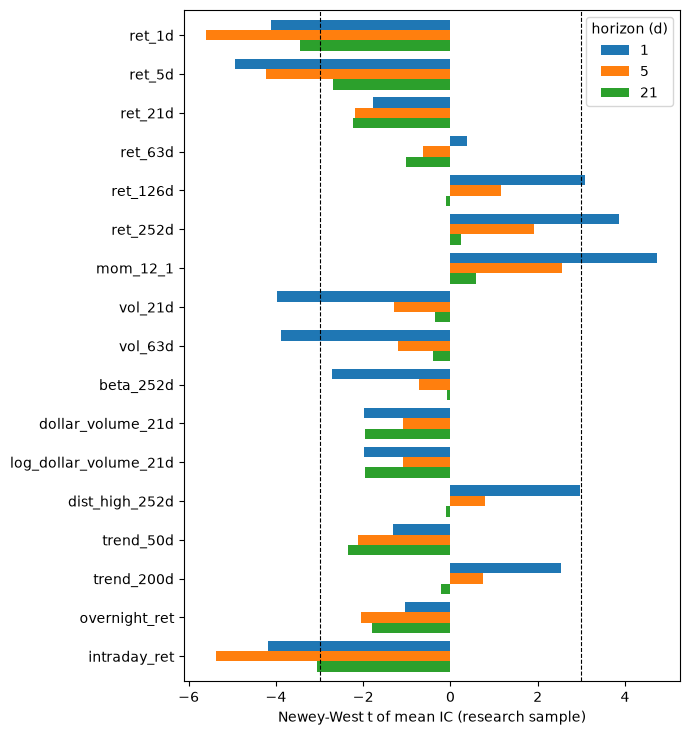

In [3]:
plots.plot_tstat_overview(ic);

**What survived.** Eleven of 51 tests are rejected by Holm, 14 by Benjamini-Yekutieli and 18 by Benjamini-Hochberg
(13 have |t| > 3). Every survivor of the strictest correction is one of two things:

- **Short-term reversal**, in the expected direction: `ret_1d` (all three horizons), `ret_5d` (1d and 5d) and
  `intraday_ret` (1d and 5d). Because `ret_1d = overnight x intraday`, and `overnight_ret` carries no IC of its own
  (|t| < 2.1 everywhere), the one-day reversal is an intraday effect: the part of the day's move made between open and
  close reverts, the overnight gap does not. The effect is concentrated at 1 to 5 days (IC about -0.009 to -0.016) and
  fades at 21 days.
- **Slow momentum and low risk at the one-day horizon**: `mom_12_1`, `ret_252d`, `vol_21d` and `vol_63d` at h = 1
  (IC +0.011 to +0.013 for momentum, about -0.012 for volatility). Their significance shrinks sharply at longer
  horizons: none of the four is significant at 21 days, and only `mom_12_1` at 5 days survives Benjamini-Hochberg.

Benjamini-Hochberg also admits `ret_126d`, `dist_high_252d`, `trend_200d` and `beta_252d` at h = 1 (|IC| below 0.010,
|t| between 2.5 and 3.1), plus `ret_5d` at 21 days, `mom_12_1` at 5 days and `intraday_ret` at 21 days. The first
three h = 1 signals and `intraday_ret` at 21 days also pass Benjamini-Yekutieli. These are suggestive, not established.

**What did not.** `ret_63d` has no IC at any horizon. Dollar volume is nominally borderline (t of about -1.97) and gone
after any adjustment. `trend_50d` has the sign opposite to its prior at 21 days (negative IC, t = -2.4), consistent
with it behaving more like a reversal than a trend signal. `overnight_ret`, `beta_252d` at 5 and 21 days, and all
`ret_21d` tests are null. A 21-day IC is small and noisy for every feature (largest |t| 3.5).

**Magnitude.** All significant ICs are small: 0.01 to 0.016 in absolute value, per-date IR below 0.1, and hit rates of
47% to 55%. This is what to expect in a liquid large-cap universe, and it is why these are baselines, not strategies.

## 2. Do the results match the pre-specified priors?

In [4]:
sign = headline[headline["expected_sign"] != 0].groupby("feature", sort=False)["sign_consistent"].agg(["sum", "count"])
sign.columns = ["horizons_with_expected_sign", "horizons"]
display(sign)

,horizons_with_expected_sign,horizons
feature,,
ret_1d,3,3
ret_5d,3,3
ret_63d,1,3
ret_126d,2,3
ret_252d,3,3
mom_12_1,3,3
vol_21d,3,3
vol_63d,3,3
dist_high_252d,2,3


Where a prior existed, the sign was right at all three horizons for `ret_1d`, `ret_5d`, `mom_12_1`, `ret_252d`,
`vol_21d` and `vol_63d`. The priors that failed are the ones the design flagged as loose: `ret_63d`, `ret_126d`,
`dist_high_252d` and `trend_200d` flip sign at 5 or 21 days (with t near zero), and `trend_50d` is wrong-signed at every
horizon. Signs are descriptive; no test depends on them.

## 3. How fast do the signals decay?

,ic_k0,t_k0,ic_last,cum_ic,half_life_days
feature,,,,,
ret_1d,-0.0092,-4.1230,0.0017,-0.0126,1.7392
ret_5d,-0.0104,-4.9320,0.0009,-0.0248,2.4971
ret_21d,-0.0039,-1.7726,0.0017,-0.0059,NaN
ret_63d,0.0009,0.3890,0.0069,0.1138,NaN
ret_126d,0.0083,3.0946,0.0107,0.2054,NaN
ret_252d,0.0113,3.8720,0.0111,0.2440,NaN
mom_12_1,0.0134,4.7442,0.0107,0.2513,NaN
vol_21d,-0.0118,-3.9650,-0.0107,-0.2263,NaN
vol_63d,-0.0122,-3.8724,-0.0114,-0.2451,NaN


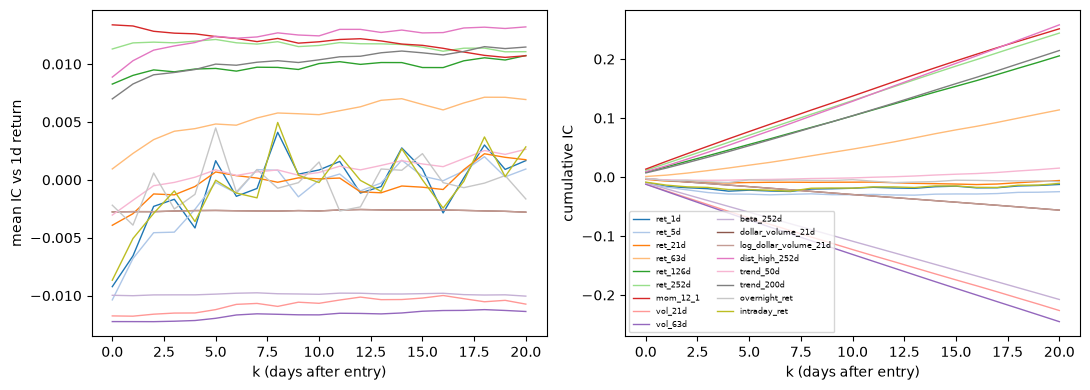

In [5]:
decay = read("ic_decay")
plots.plot_decay(decay)
display(half_life_table(OUT).round(4))

**Reversal signals** (`ret_1d`, `ret_5d`, `intraday_ret`) have the only measurable half-lives: about 1.7 to 2.5
trading days. By day 5 after entry their IC is close to zero. A reversal portfolio therefore has to
be traded within days, which is also why its turnover is high (below).

**Momentum, volatility and trend signals do not halve within 21 days.** Their IC is flat (momentum about 0.011 to 0.013,
volatility about -0.012 across the whole window), so no half-life is reported. This only says the *daily* IC persists.
It does not say the 21-day IC is as large: the IC against the cumulative 21-day return is about half the daily IC
(`mom_12_1`: 0.0134 at h = 1, 0.0063 at h = 21). The two statistics measure different things and the gap was not
resolved here; I checked that it is not explained by index leavers dropping out of the shifted returns.
Caveat: shifted returns exist only for names still in the index at `t + k`.

## 4. Gross long-short spreads and turnover

In [6]:
ls = read("long_short").merge(read("turnover"), on=["feature", "horizon"])
cols = ["feature", "horizon", "n_periods", "gross_raw_mean", "gross_raw_sharpe", "gross_raw_nw_t", "gross_oriented_sharpe",
        "reject_holm", "reject_bh", "monotonicity", "D1_turnover", "D10_turnover"]
display(ls[cols].round(4))

,feature,horizon,n_periods,gross_raw_mean,gross_raw_sharpe,gross_raw_nw_t,gross_oriented_sharpe,reject_holm,reject_bh,monotonicity,D1_turnover,D10_turnover
0,ret_1d,1,5766,-0.0007,-0.8081,-3.6783,0.8081,True,True,-1.0000,0.8484,0.8559
1,ret_1d,5,1154,-0.0029,-0.6009,-2.7940,0.6009,False,True,-0.9515,0.8539,0.8675
2,ret_1d,21,275,-0.0024,-0.1431,-0.7235,0.1431,False,False,-0.7576,0.8526,0.8797
3,ret_5d,1,5766,-0.0008,-0.8624,-4.0827,0.8624,True,True,-1.0000,0.3952,0.4028
4,ret_5d,5,1154,-0.0032,-0.6907,-3.3705,0.6907,True,True,-0.9636,0.8586,0.8763
5,ret_5d,21,275,-0.0035,-0.1661,-0.8149,0.1661,False,False,-0.8424,0.8502,0.8655
6,ret_21d,1,5766,-0.0004,-0.4476,-2.0995,NaN,False,False,-0.9879,0.1917,0.2048
7,ret_21d,5,1154,-0.0014,-0.2643,-1.4437,NaN,False,False,-0.9394,0.4307,0.4563
8,ret_21d,21,275,-0.0049,-0.2139,-1.2519,NaN,False,False,-0.9515,0.8516,0.8813
9,ret_63d,1,5766,-0.0004,-0.3855,-1.7821,-0.3855,False,False,-0.9758,0.1114,0.1233


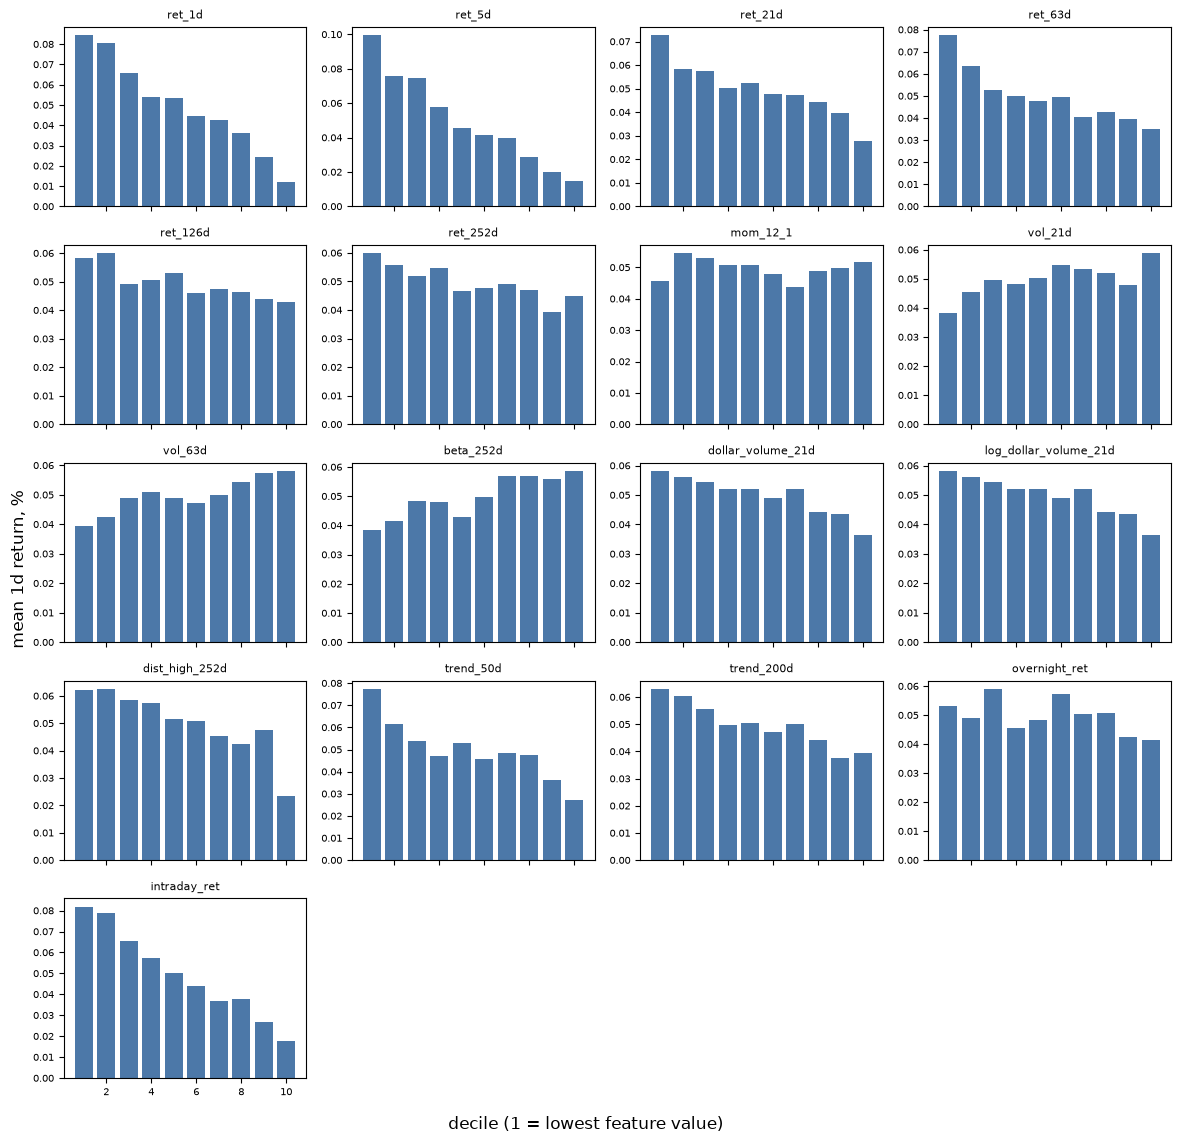

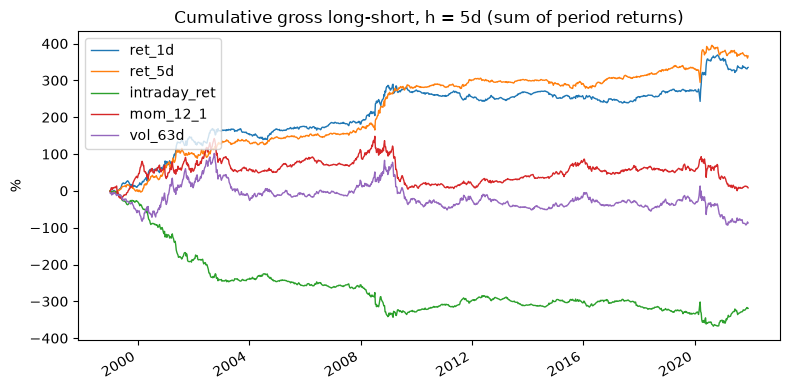

In [7]:
plots.plot_decile_means(read("decile_returns"), 1)
spread = pd.read_parquet(OUT / "cache" / "long_short_h5.parquet")
plots.plot_long_short(spread, 5, ["ret_1d", "ret_5d", "intraday_ret", "mom_12_1", "vol_63d"]);

(`gross_raw_*` is D10 minus D1 on the raw feature, no costs; `gross_oriented_*` multiplies by the expected sign.
Turnover is one-way, per leg, between rebalances.)

- **Only the reversal spreads are statistically distinguishable from zero**, and only at short horizons: `ret_5d` at
  h = 1 has a gross Sharpe of 0.86 (oriented), `ret_1d` 0.81 and `intraday_ret` -0.75 (raw D10 - D1, no prior), all
  rejected by Holm at the one-day horizon, and `ret_5d` also at 5 days (0.69). At 21 days no spread is significant.
- **These spreads are the least tradable.** One-way turnover is 85% per leg per rebalance for `ret_1d` and
  `intraday_ret` (daily), and still 85% for `ret_5d` at the 5-day rebalance. The gross daily mean spread is under
  0.1% (8 basis points a day for `ret_5d`), which a realistic cost of even a few basis points per side would erode.
  Costs are not modelled here.
- **Significant IC does not imply a significant spread.** `mom_12_1`, `ret_252d`, `vol_21d` and `vol_63d` have
  clearly non-zero ICs at h = 1 but gross Sharpes of about 0.05, -0.12, 0.15 and 0.13 (raw), none significant. For
  volatility the decile means rise with volatility (3.8 bp a day in the lowest decile to 5.9 bp in the highest)
  although the rank IC is negative: the equal-weight mean is pulled up by a few high-volatility winners, while the
  rank correlation sees the typical stock. Momentum deciles are flat-to-U-shaped (monotonicity -0.16). The IC is
  picking up a broad ranking effect that the extreme deciles do not monetise in this sample.
- The slow signals turn over about 4% to 15% a day at h = 1 and 22% to 59% per 21-day rebalance (`vol_21d` is the
  highest); the reversal and intraday signals are far higher at 85%.

## 5. Fama-MacBeth

In [8]:
fm_uni, fm_multi = read("fama_macbeth_univariate"), read("fama_macbeth_multivariate")
display(fm_uni[fm_uni["horizon"] == 1][["feature", "coef_mean", "nw_t", "avg_r2", "avg_n", "reject_holm", "reject_bh"]].round(5))
display(fm_multi[fm_multi["regressor"] != "const"][["horizon", "regressor", "coef_mean", "nw_t", "avg_r2", "avg_vif"]].round(5))
display(read("fm_collinearity").groupby("regressor", sort=False)[["avg_vif", "avg_condition_number", "avg_abs_pairwise_corr"]].first().round(2))

,feature,coef_mean,nw_t,avg_r2,avg_n,reject_holm,reject_bh
0,ret_1d,-0.00020,-3.62773,0.02580,501.38120,True,True
3,ret_5d,-0.00026,-4.27137,0.02848,501.36420,True,True
6,ret_21d,-0.00012,-1.95399,0.03001,501.21939,False,False
9,ret_63d,-0.00011,-1.69766,0.03427,500.72477,False,False
12,ret_126d,-0.00005,-0.65238,0.04048,499.94797,False,False
15,ret_252d,-0.00005,-0.66018,0.04663,498.25494,False,False
18,mom_12_1,-0.00000,-0.03347,0.04594,498.25494,False,False
21,vol_21d,0.00005,0.61956,0.05555,501.26483,False,False
24,vol_63d,0.00005,0.63556,0.06265,500.86837,False,False
27,beta_252d,0.00007,0.77298,0.07775,498.94294,False,False


,horizon,regressor,coef_mean,nw_t,avg_r2,avg_vif
1,1,ret_5d,-0.00021,-4.86334,0.12302,1.36686
2,1,mom_12_1,0.00009,1.99485,0.12302,2.34229
3,1,vol_63d,-0.00002,-0.41672,0.12302,2.17242
4,1,log_dollar_volume_21d,-0.00003,-1.36172,0.12302,1.10015
5,1,dist_high_252d,-0.00013,-1.98994,0.12302,3.40123
6,1,overnight_ret,0.00001,0.44266,0.12302,1.19451
8,5,ret_5d,-0.00056,-3.89625,0.12978,1.36688
9,5,mom_12_1,0.00044,2.15063,0.12978,2.34229
10,5,vol_63d,-0.00013,-0.52494,0.12978,2.17264
11,5,log_dollar_volume_21d,-0.00017,-1.51727,0.12978,1.10016


,avg_vif,avg_condition_number,avg_abs_pairwise_corr
regressor,,,
ret_5d,1.37,14.25,0.23
mom_12_1,2.34,14.25,0.23
vol_63d,2.17,14.25,0.23
log_dollar_volume_21d,1.10,14.25,0.23
dist_high_252d,3.40,14.25,0.23
overnight_ret,1.19,14.25,0.23


Coefficients are the mean cross-sectional return (per h days) for a 1 standard deviation higher feature value.

- **Univariately**, only reversal survives correction at h = 1: `ret_1d`, `ret_5d` and `intraday_ret` (about -2 to
  -2.6 basis points a day per SD, t about -3.6 to -4.3). Momentum, volatility and beta have no significant slope
  although their rank ICs are significant: the regressions use raw returns, where outliers and the market
  component dominate (average R-squared of 5% to 8% for volatility and beta, probably market-direction exposure on
  large-move days rather than predictive power).
- **Multivariately** (one representative per family; average VIF at most 3.4, condition number about 14, so
  collinearity is mild), `ret_5d` remains strongly negative at all horizons (t = -4.9, -3.9, -3.0), `mom_12_1` is
  weakly positive (t about 2.0, 2.2, 1.4) and `dist_high_252d` weakly negative (t about -2.0, -2.0, -1.3).
  Controlling for the other families, volatility, size and the overnight return add nothing. The multivariate
  results are not adjusted for multiple testing, so the momentum and 52-week-high coefficients should be read as
  unconfirmed.

## 6. Cross-signal structure

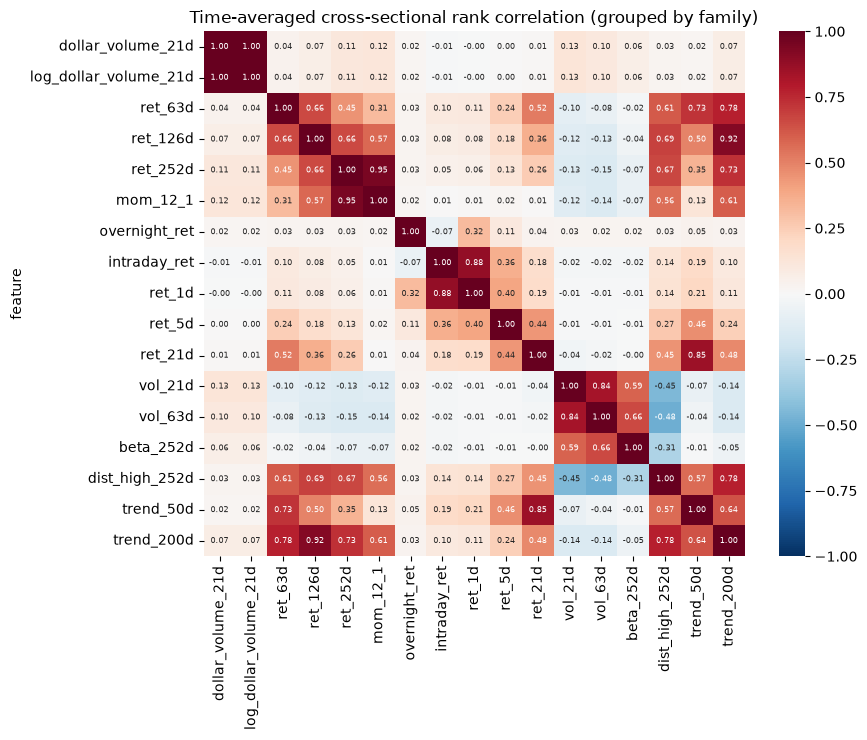

In [9]:
corr = read("signal_correlation").set_index("feature")
plots.plot_correlation(corr);

The features are far fewer than the 17 columns suggest. `dollar_volume_21d` and its log are rank-identical (the
effective test family is 48). `mom_12_1` and `ret_252d` correlate at 0.95, `ret_126d` and `trend_200d` at 0.92,
`intraday_ret` and `ret_1d` at 0.88, `ret_21d` and `trend_50d` at 0.85 and `vol_21d` and `vol_63d` at 0.84. The
significant results therefore reflect three or four underlying effects (short-term reversal, medium-to-long-term
momentum, low volatility), not eleven independent discoveries.

## 7. Stability and sensitivity

label,dotcom,gfc,y2010_2019,post2020,first,second
feature,,,,,,
ret_1d,-0.0255,-0.0129,-0.0052,-0.0144,-0.0178,-0.0060
ret_5d,-0.0236,-0.0167,-0.0118,-0.0081,-0.0207,-0.0103
intraday_ret,-0.0284,-0.0061,-0.0048,-0.0072,-0.0164,-0.0049
mom_12_1,0.0299,0.0136,0.0148,0.0005,0.0181,0.0121
ret_252d,0.0220,0.0104,0.0118,-0.0000,0.0136,0.0095
vol_21d,-0.0214,-0.0139,-0.0068,-0.0046,-0.0104,-0.0054
vol_63d,-0.0182,-0.0155,-0.0091,-0.0006,-0.0083,-0.0074
ret_126d,0.0038,0.0160,0.0038,0.0068,0.0077,0.0049
dist_high_252d,0.0104,0.0114,0.0046,0.0021,0.0055,0.0042


max_abs_change_ic_mean    0.000232
max_abs_change_nw_t       0.037523
dtype: float64

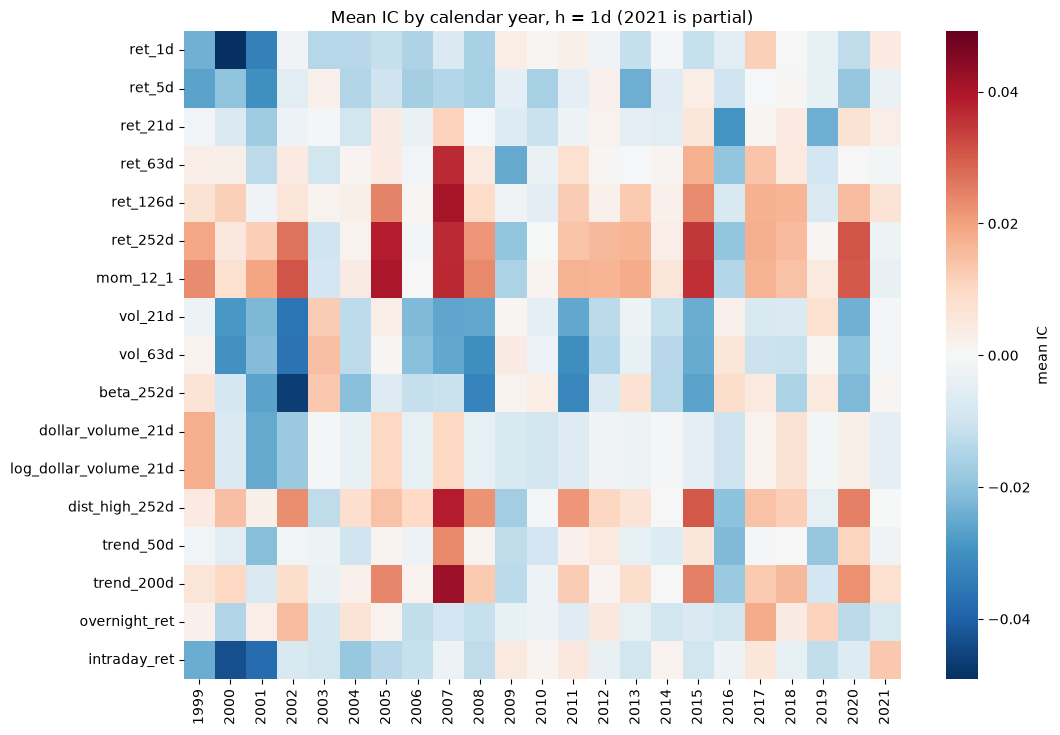

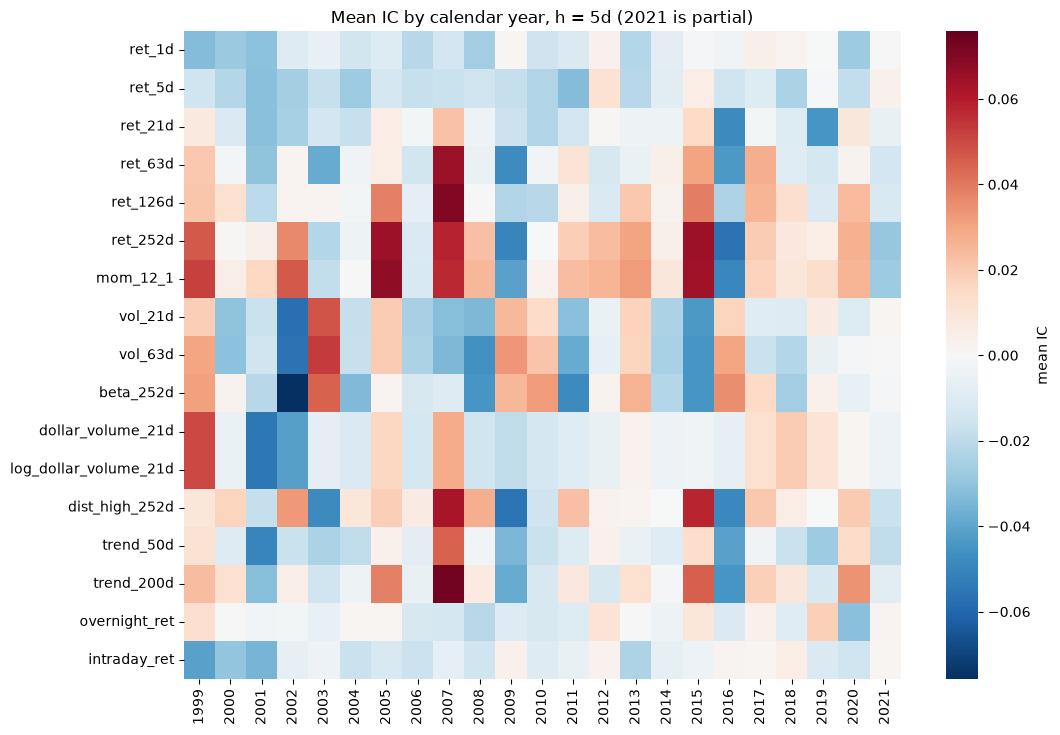

In [10]:
stability = read("ic_stability")
for h in (1, 5):
    plots.plot_ic_year_heatmap(stability, h)
names = ["ret_1d", "ret_5d", "intraday_ret", "mom_12_1", "ret_252d", "vol_21d", "vol_63d", "ret_126d", "dist_high_252d"]
display(period_table(OUT, 5, names).round(4))
display(terminal_effect(OUT))

- **Effects are strongest early and fade.** For the 5-day horizon, reversal IC falls from about -0.024 in
  1999-2002 to about -0.008 post-2020 (`ret_5d`), momentum (`mom_12_1`) from +0.030 to +0.0005, and volatility
  (`vol_63d`) from -0.018 to about zero. Every signal shown has a larger IC in the first half of the sample than in the second. The dot-com
  period contributes disproportionately; the post-2020 window is only 23 months (483 dates), so it is a weak test.
- **Sign flips in single years are common** for momentum and trend (for example 2009 and 2016 are strongly negative),
  which is the familiar momentum-crash pattern.
- **Delisted-stock exits do not matter.** Excluding `fwd_terminal` rows changes mean IC by at most 0.0002 and the
  t-statistic by at most 0.04 across all 51 tests.

## 8. Conclusions and limitations

1. Short-term reversal (`ret_1d`, `ret_5d`, `intraday_ret`) is the one result that is robust to every correction,
   economically sensible, and consistent across IC, deciles and Fama-MacBeth. It is also fast (half-life about two days),
   high turnover and its strength has declined over time.
2. Momentum and low volatility have small, persistent, significant rank ICs at the one-day horizon, but their
   long-short spreads are not significant and their significance disappears at 21 days. They are candidates for
   combination, not stand-alone signals.
3. Everything else (63-day momentum, trend, size/liquidity proxies, overnight return, beta at longer horizons) is
   null in this sample. These are reported, not dropped.
4. All results are gross, use equal-weighted deciles and are research-sample only; the 2022 onward holdout has not
   been read. Absolute IC levels are small and have shrunk over time, so out-of-sample expectations should be modest.